# Notebook 02: Complete Line A on Clean Hourly Data (Train/Val/Test + 5-Fold CV)
## 1. Load Clean Hourly Dataset from Notebook 01

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor, ExtraTreesClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix, roc_curve
from xgboost import XGBRegressor, XGBClassifier
df = pd.read_csv(PROJECT_ROOT / '06_Data' / 'riyadh_hourly_clean_tvt.csv')
df['ts'] = pd.to_datetime(df['ts'])
target_cols = [c for c in df.columns if c.startswith('target_')]
feature_cols = [c for c in df.columns if c not in ['ts'] + target_cols]
print(f'Clean hourly rows: {len(df):,} | Features: {len(feature_cols)}')

Clean hourly rows: 86,928 | Features: 115


## 2. Hourly Train (70%) / 360h Gap / Val (15%) / 360h Gap / Test (15%) Split

In [2]:
N = len(df); GAP_H = 360
tr_end = int(N * 0.70); val_start = tr_end + GAP_H; val_end = int(N * 0.85); te_start = val_end + GAP_H
# Synoptic 6-hour stride (00,06,12,18 UTC) for fast multi-seed training
STRIDE = 6
train_df = df.iloc[:tr_end:STRIDE].reset_index(drop=True)
val_df = df.iloc[val_start:val_end:STRIDE].reset_index(drop=True)
test_df = df.iloc[te_start::STRIDE].reset_index(drop=True)
imp = SimpleImputer(strategy='median'); pt = PowerTransformer(method='yeo-johnson')
X_tr = pt.fit_transform(imp.fit_transform(train_df[feature_cols].values))
X_va = pt.transform(imp.transform(val_df[feature_cols].values))
X_te = pt.transform(imp.transform(test_df[feature_cols].values))
print(f'Synoptic 6h Train: {X_tr.shape} | Val: {X_va.shape} | Test: {X_te.shape}')

Synoptic 6h Train: (10142, 115) | Val: (2114, 115) | Test: (2114, 115)


## 3. Calibration, Alert-Lift & 5-Fold Rolling-Origin CV Helpers

In [3]:
HORIZONS_H = [24, 72, 168, 216, 360]
SEEDS = [42, 123, 456]
def platt_cal(va_s, va_y, te_s):
    if len(np.unique(va_y)) < 2 or np.std(va_s) < 1e-12: return np.full(len(te_s), float(np.mean(va_y)))
    lr = LogisticRegression(C=1.0, max_iter=1000).fit(np.clip(va_s,-30,30).reshape(-1,1), va_y)
    return np.clip(lr.predict_proba(np.clip(te_s,-30,30).reshape(-1,1))[:,1], 1e-6, 1-1e-6)
def rec10(y, p):
    k = max(1, int(np.ceil(len(y)*0.10))); idx = np.argsort(p)[::-1][:k]
    r = float(np.sum(y[idx])/max(1,np.sum(y))); return r, r/0.10
def make_cv_folds(n, gap_rows=60, k=5):
    m = int(n*0.40); st = (n-m)//k
    return [(np.arange(0, m+i*st-gap_rows), np.arange(m+i*st, m+(i+1)*st if i<k-1 else n)) for i in range(k)]
cv_folds = make_cv_folds(len(X_tr), 60, 5)
print('5-Fold CV ready (60-step = 360h gap).')

5-Fold CV ready (60-step = 360h gap).


## 4. 5-Fold Rolling-Origin CV Inside 70% Train (All 5 Horizons)

In [4]:
cv_rows = []
for h in HORIZONS_H:
    y_cv = train_df[f'target_evt_any_{h}h'].values.astype(int)
    for mn, fn in [('LogReg_Bal', lambda s: LogisticRegression(C=0.2, class_weight='balanced', max_iter=1000)), ('RandomForest', lambda s: RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=8, class_weight='balanced', random_state=s, n_jobs=-1)), ('ExtraTrees', lambda s: ExtraTreesClassifier(n_estimators=100, max_depth=8, min_samples_leaf=8, class_weight='balanced', random_state=s, n_jobs=-1)), ('HistGB', lambda s: HistGradientBoostingClassifier(max_iter=120, max_depth=5, min_samples_leaf=15, l2_regularization=2.0, random_state=s)), ('XGBoost', lambda s: XGBClassifier(n_estimators=120, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0, random_state=s, n_jobs=-1, eval_metric='logloss'))]:
        oy, op = [], []
        for ti, vi in cv_folds:
            if len(np.unique(y_cv[ti])) < 2: continue
            m = fn(42).fit(X_tr[ti], y_cv[ti]); oy.append(y_cv[vi]); op.append(m.predict_proba(X_tr[vi])[:,1])
        yc, pc = np.concatenate(oy), np.concatenate(op)
        cv_rows.append({'Horizon_H': h, 'Days': h//24, 'Model': mn, 'CV_ROC': round(roc_auc_score(yc,pc),4), 'CV_PR': round(average_precision_score(yc,pc),4)})
cv_df = pd.DataFrame(cv_rows); cv_df.to_csv(RESULTS_DIR / 'nb02_line_a_5fold_cv_hourly.csv', index=False)
print(cv_df.to_string(index=False))

 Horizon_H  Days        Model  CV_ROC  CV_PR
        24     1   LogReg_Bal  0.8527 0.6911
        24     1 RandomForest  0.8611 0.7003
        24     1   ExtraTrees  0.8598 0.6995
        24     1       HistGB  0.8469 0.6798
        24     1      XGBoost  0.8619 0.7028
        72     3   LogReg_Bal  0.7875 0.7514
        72     3 RandomForest  0.8047 0.7716
        72     3   ExtraTrees  0.8097 0.7728
        72     3       HistGB  0.7832 0.7339
        72     3      XGBoost  0.8030 0.7618
       168     7   LogReg_Bal  0.7871 0.8592
       168     7 RandomForest  0.7822 0.8585
       168     7   ExtraTrees  0.7992 0.8701
       168     7       HistGB  0.7509 0.8236
       168     7      XGBoost  0.7630 0.8362
       216     9   LogReg_Bal  0.7937 0.8908
       216     9 RandomForest  0.7753 0.8786
       216     9   ExtraTrees  0.8043 0.8956
       216     9       HistGB  0.7278 0.8452
       216     9      XGBoost  0.7476 0.8678
       360    15   LogReg_Bal  0.8052 0.9421
       360

## 5. 5-Fold CV ROC-AUC Across 1–15 Days

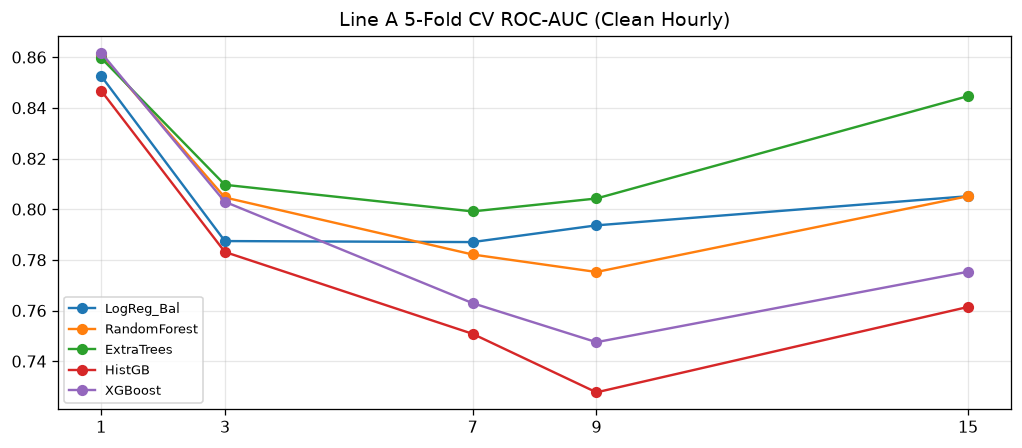

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for m in cv_df['Model'].unique():
    s = cv_df[cv_df['Model']==m]; ax.plot(s['Days'], s['CV_ROC'], marker='o', label=m)
ax.set_xticks([1,3,7,9,15]); ax.set_title('Line A 5-Fold CV ROC-AUC (Clean Hourly)'); ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout()

## 6. Train / Val Calibration & Test Evaluation: Baselines (Classification)

In [6]:
cls_rows = []
for h in HORIZONS_H:
    y_tr = train_df[f'target_evt_any_{h}h'].values.astype(int)
    y_va = val_df[f'target_evt_any_{h}h'].values.astype(int)
    y_te = test_df[f'target_evt_any_{h}h'].values.astype(int)
    b_ref = brier_score_loss(y_te, np.full(len(y_te), float(np.mean(y_tr))))
    pers_p = platt_cal(val_df['dust_rate_720h'].values, y_va, test_df['dust_rate_720h'].values)
    mc_map = pd.Series(y_tr).groupby(train_df['ts'].dt.month).mean().to_dict()
    mc_va = np.array([mc_map.get(m, np.mean(y_tr)) for m in val_df['ts'].dt.month])
    mc_te = np.array([mc_map.get(m, np.mean(y_tr)) for m in test_df['ts'].dt.month])
    mc_p = platt_cal(mc_va, y_va, mc_te)
    lr = LogisticRegression(C=0.2, class_weight='balanced', max_iter=1000).fit(X_tr, y_tr)
    lr_p = platt_cal(lr.predict_proba(X_va)[:,1], y_va, lr.predict_proba(X_te)[:,1])
    for mn, p, vr in [('Persistence_Cal', pers_p, val_df['dust_rate_720h'].values), ('MonthClimo_Cal', mc_p, mc_va), ('LogReg_Bal_Cal', lr_p, lr.predict_proba(X_va)[:,1])]:
        br = brier_score_loss(y_te, p); r10, l10 = rec10(y_te, p)
        cls_rows.append({'Horizon_H': h, 'Days': h//24, 'Model': mn, 'Val_ROC': round(roc_auc_score(y_va, vr),4), 'Test_ROC': round(roc_auc_score(y_te,p),4), 'ROC_sd': 0.0, 'Test_PR': round(average_precision_score(y_te,p),4), 'Brier': round(br,4), 'BSS': round(1-br/b_ref,4), 'Rec10': round(r10,4), 'Lift10': round(l10,2)})
print('Hourly baselines evaluated.')

Hourly baselines evaluated.


## 7. Line A Tree & Boosting Models (3-Seed Mean ± SD on Held-Out Test)

In [7]:
te_probs_168 = {}
for h in HORIZONS_H:
    y_tr = train_df[f'target_evt_any_{h}h'].values.astype(int)
    y_va = val_df[f'target_evt_any_{h}h'].values.astype(int)
    y_te = test_df[f'target_evt_any_{h}h'].values.astype(int)
    b_ref = brier_score_loss(y_te, np.full(len(y_te), float(np.mean(y_tr))))
    pw = float(np.sum(y_tr==0)/max(1,np.sum(y_tr==1)))
    specs = [('RandomForest_Cal', lambda s: RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=8, class_weight='balanced', random_state=s, n_jobs=-1)), ('ExtraTrees_Cal', lambda s: ExtraTreesClassifier(n_estimators=100, max_depth=8, min_samples_leaf=8, class_weight='balanced', random_state=s, n_jobs=-1)), ('HistGB_Cal', lambda s: HistGradientBoostingClassifier(max_iter=120, max_depth=5, min_samples_leaf=15, l2_regularization=2.0, random_state=s)), ('XGBoost_Cal', lambda s: XGBClassifier(n_estimators=120, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pw, reg_lambda=2.0, random_state=s, n_jobs=-1, eval_metric='logloss'))]
    for mn, fn in specs:
        vrocs, trocs, prs, brs, bsss, r10s, l10s = [], [], [], [], [], [], []
        for s in SEEDS:
            m = fn(s).fit(X_tr, y_tr); vp = m.predict_proba(X_va)[:,1]; tp = platt_cal(vp, y_va, m.predict_proba(X_te)[:,1])
            if h == 168 and s == 42: te_probs_168[mn] = tp
            vrocs.append(roc_auc_score(y_va,vp)); trocs.append(roc_auc_score(y_te,tp)); prs.append(average_precision_score(y_te,tp))
            br = brier_score_loss(y_te,tp); brs.append(br); bsss.append(1-br/b_ref); r10, l10 = rec10(y_te,tp); r10s.append(r10); l10s.append(l10)
        cls_rows.append({'Horizon_H': h, 'Days': h//24, 'Model': mn, 'Val_ROC': round(np.mean(vrocs),4), 'Test_ROC': round(np.mean(trocs),4), 'ROC_sd': round(np.std(trocs),4), 'Test_PR': round(np.mean(prs),4), 'Brier': round(np.mean(brs),4), 'BSS': round(np.mean(bsss),4), 'Rec10': round(np.mean(r10s),4), 'Lift10': round(np.mean(l10s),2)})
cls_df = pd.DataFrame(cls_rows); cls_df.to_csv(RESULTS_DIR / 'nb02_line_a_classification_hourly.csv', index=False)
print(cls_df[['Days','Model','Val_ROC','Test_ROC','Test_PR','BSS','Lift10']].to_string(index=False))

 Days            Model  Val_ROC  Test_ROC  Test_PR     BSS  Lift10
    1  Persistence_Cal   0.6214    0.5701   0.0966  0.1553    1.66
    1   MonthClimo_Cal   0.5890    0.6427   0.1198  0.1043    1.85
    1   LogReg_Bal_Cal   0.8378    0.7955   0.3067  0.2581    3.91
    3  Persistence_Cal   0.5636    0.5451   0.2125  0.1540    1.42
    3   MonthClimo_Cal   0.5786    0.6411   0.2815  0.1729    2.43
    3   LogReg_Bal_Cal   0.7507    0.6761   0.3529  0.3006    2.54
    7  Persistence_Cal   0.5104    0.5436   0.4279  0.1111    1.54
    7   MonthClimo_Cal   0.5571    0.6576   0.5480  0.1935    1.89
    7   LogReg_Bal_Cal   0.6750    0.6626   0.5293  0.2677    1.91
    9  Persistence_Cal   0.4794    0.5410   0.5092  0.0774    1.65
    9   MonthClimo_Cal   0.5520    0.6663   0.6411  0.1941    1.86
    9   LogReg_Bal_Cal   0.6786    0.6569   0.6152  0.2509    1.82
   15  Persistence_Cal   0.4120    0.4721   0.5913  0.0055    1.59
   15   MonthClimo_Cal   0.6300    0.6648   0.7672  0.1784    

## 8. Validation vs Test ROC-AUC Decay (1–15 Days)

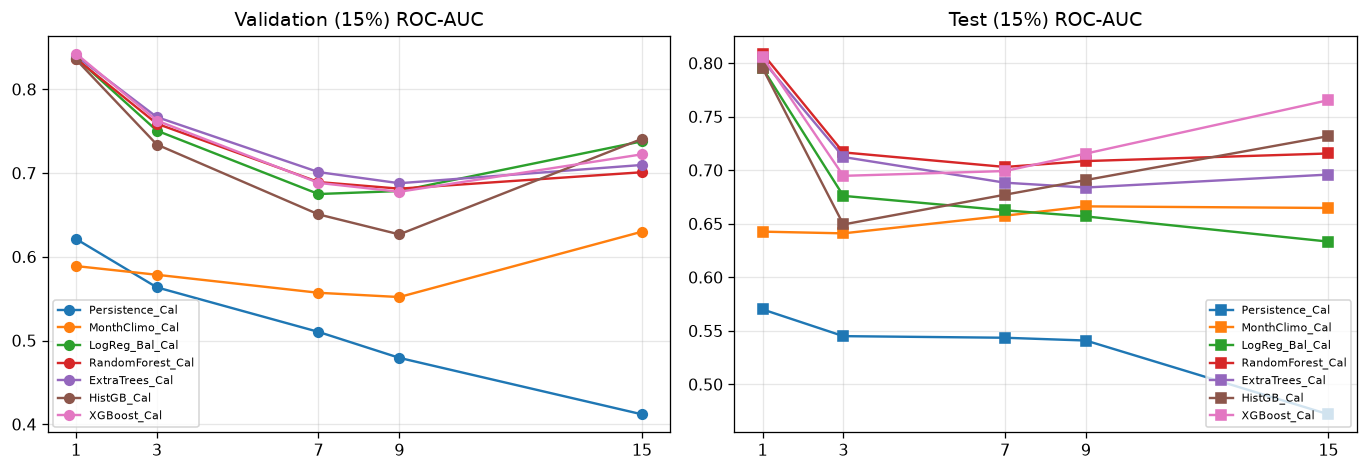

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for m in cls_df['Model'].unique():
    s = cls_df[cls_df['Model']==m]
    axes[0].plot(s['Days'], s['Val_ROC'], marker='o', label=m); axes[1].plot(s['Days'], s['Test_ROC'], marker='s', label=m)
axes[0].set_title('Validation (15%) ROC-AUC'); axes[1].set_title('Test (15%) ROC-AUC')
for ax in axes: ax.set_xticks([1,3,7,9,15]); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout()

## 9. Test PR-AUC & Brier Skill Score (BSS) Across 1–15 Days

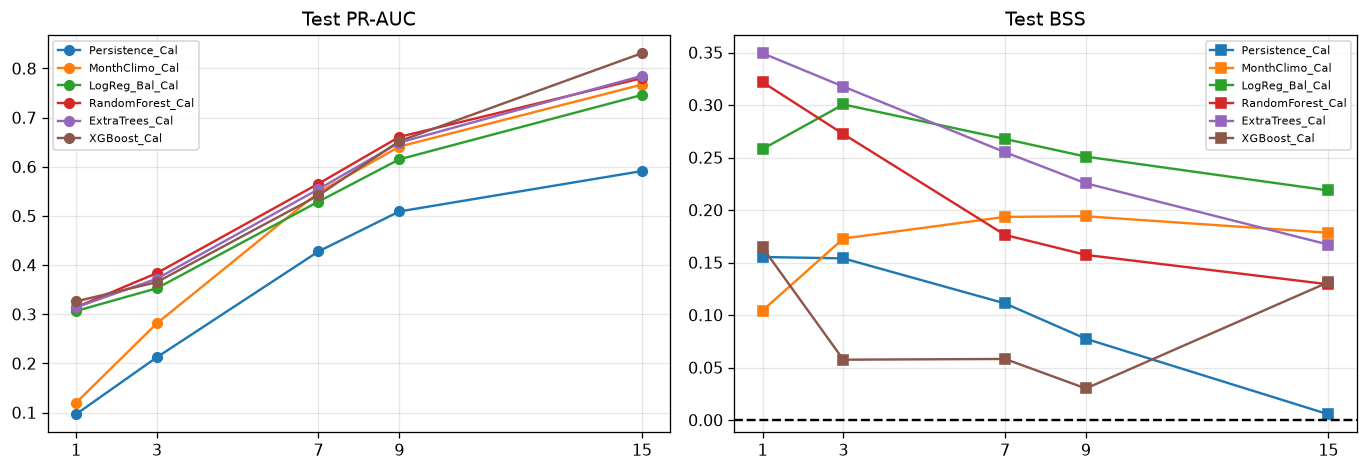

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for m in ['Persistence_Cal','MonthClimo_Cal','LogReg_Bal_Cal','RandomForest_Cal','ExtraTrees_Cal','XGBoost_Cal']:
    s = cls_df[cls_df['Model']==m]
    axes[0].plot(s['Days'], s['Test_PR'], marker='o', label=m); axes[1].plot(s['Days'], s['BSS'], marker='s', label=m)
axes[1].axhline(0, color='black', ls='--'); axes[0].set_title('Test PR-AUC'); axes[1].set_title('Test BSS')
for ax in axes: ax.set_xticks([1,3,7,9,15]); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout()

## 10. 168h (7-Day) Test ROC Curves

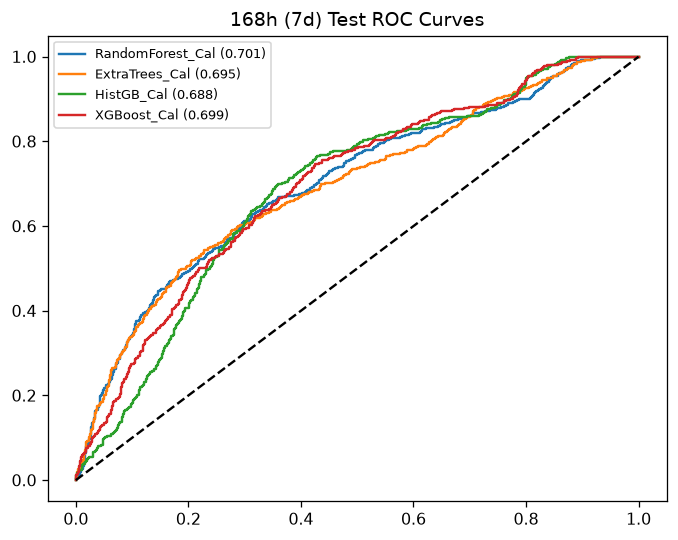

In [10]:
y_te168 = test_df['target_evt_any_168h'].values.astype(int)
fig, ax = plt.subplots(figsize=(6, 4.8))
for m, p in te_probs_168.items():
    fpr, tpr, _ = roc_curve(y_te168, p); ax.plot(fpr, tpr, label=f'{m} ({roc_auc_score(y_te168,p):.3f})')
ax.plot([0,1],[0,1],'k--'); ax.set_title('168h (7d) Test ROC Curves'); ax.legend(fontsize=8); plt.tight_layout()

## 11. 168h Calibration Reliability Diagram

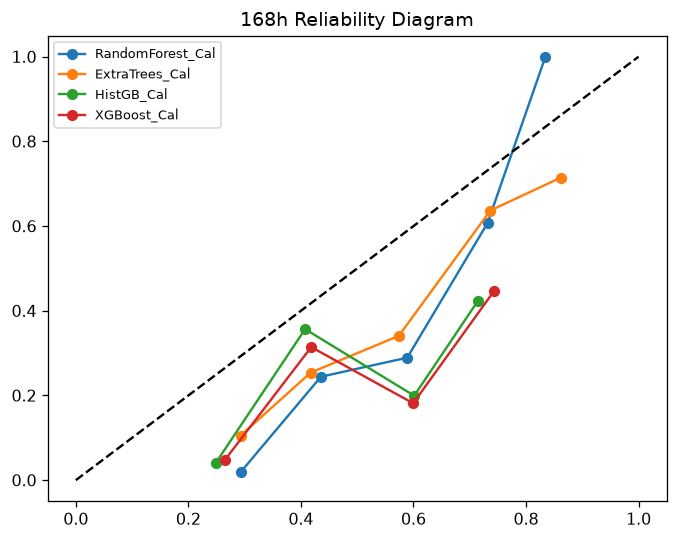

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.8))
for m, p in te_probs_168.items():
    bins = np.linspace(0,1,7); bi = np.digitize(p,bins)-1
    ax.plot([p[bi==i].mean() if np.any(bi==i) else np.nan for i in range(6)], [y_te168[bi==i].mean() if np.any(bi==i) else np.nan for i in range(6)], marker='o', label=m)
ax.plot([0,1],[0,1],'k--'); ax.set_title('168h Reliability Diagram'); ax.legend(fontsize=8); plt.tight_layout()

## 12. Validation-Tuned Confusion Matrix (168h RandomForest)

In [12]:
m_rf = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=8, class_weight='balanced', random_state=42, n_jobs=-1).fit(X_tr, train_df['target_evt_any_168h'].values.astype(int))
vp_rf = platt_cal(m_rf.predict_proba(X_va)[:,1], val_df['target_evt_any_168h'].values.astype(int), m_rf.predict_proba(X_va)[:,1])
tau = np.quantile(vp_rf, 0.80)
print(f'Val Top-20% tau={tau:.3f} -> Test Confusion Matrix:\n{confusion_matrix(y_te168, (te_probs_168["RandomForest_Cal"]>=tau).astype(int))}')

Val Top-20% tau=0.755 -> Test Confusion Matrix:
[[1328   47]
 [ 621  118]]


## 13. Continuous Clean-PM10 Regression (All 5 Horizons)

In [13]:
reg_rows = []
for h in HORIZONS_H:
    y_tr = train_df[f'target_avg_pm10_{h}h'].values; y_te = test_df[f'target_avg_pm10_{h}h'].values
    med_p = np.full(len(y_te), np.median(y_tr)); pers_p = test_df['pm10_clean_ugm3'].values
    mc_map = pd.Series(y_tr).groupby(train_df['ts'].dt.month).mean().to_dict()
    mc_p = np.array([mc_map.get(m, np.mean(y_tr)) for m in test_df['ts'].dt.month])
    r_p = np.expm1(np.clip(Ridge(alpha=50.0).fit(X_tr, np.log1p(np.maximum(y_tr,0))).predict(X_te), 0, 10))
    for mn, p in [('Trivial_Median', med_p), ('Persistence', pers_p), ('MonthClimo', mc_p), ('Ridge_log1p', r_p)]:
        reg_rows.append({'Horizon_H': h, 'Days': h//24, 'Model': mn, 'R2': round(r2_score(y_te,p),4), 'RMSE': round(root_mean_squared_error(y_te,p),2), 'RMSE_sd': 0.0, 'MAE': round(mean_absolute_error(y_te,p),2)})
    for mn, fn in [('RandomForest', lambda s: RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=8, random_state=s, n_jobs=-1)), ('ExtraTrees', lambda s: ExtraTreesRegressor(n_estimators=100, max_depth=8, min_samples_leaf=8, random_state=s, n_jobs=-1)), ('HistGB', lambda s: HistGradientBoostingRegressor(max_iter=120, max_depth=5, min_samples_leaf=15, l2_regularization=2.0, random_state=s)), ('XGBoost', lambda s: XGBRegressor(n_estimators=120, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0, random_state=s, n_jobs=-1))]:
        r2s, rms, mas = [], [], []
        for s in SEEDS:
            p = np.expm1(np.clip(fn(s).fit(X_tr, np.log1p(np.maximum(y_tr,0))).predict(X_te), 0, 10))
            r2s.append(r2_score(y_te,p)); rms.append(root_mean_squared_error(y_te,p)); mas.append(mean_absolute_error(y_te,p))
        reg_rows.append({'Horizon_H': h, 'Days': h//24, 'Model': mn, 'R2': round(np.mean(r2s),4), 'RMSE': round(np.mean(rms),2), 'RMSE_sd': round(np.std(rms),2), 'MAE': round(np.mean(mas),2)})
reg_df = pd.DataFrame(reg_rows); reg_df.to_csv(RESULTS_DIR / 'nb02_line_a_regression_hourly.csv', index=False)
print(reg_df[['Days','Model','R2','RMSE','MAE']].to_string(index=False))

 Days          Model        R2   RMSE    MAE
    1 Trivial_Median   -0.0056  20.86   5.69
    1    Persistence   -5.6066  53.48   9.10
    1     MonthClimo   -4.9397  50.71  38.57
    1    Ridge_log1p   -4.8101  50.15  36.11
    1   RandomForest   -0.8806  28.52  16.35
    1     ExtraTrees   -0.6029  26.34  13.94
    1         HistGB   -2.3829  38.26  21.79
    1        XGBoost   -1.7995  34.80  21.00
    3 Trivial_Median   -0.0079  13.46   5.38
    3    Persistence  -15.6903  54.77   9.50
    3     MonthClimo  -11.8167  48.00  37.28
    3    Ridge_log1p   -4.0366  30.09  23.62
    3   RandomForest  -11.2619  46.84  37.88
    3     ExtraTrees   -3.2474  27.63  21.72
    3         HistGB  -34.7631  78.71  66.47
    3        XGBoost  -12.3263  48.85  37.67
    7 Trivial_Median   -0.6741  11.80  10.64
    7    Persistence  -35.4397  55.06   9.30
    7     MonthClimo  -25.6976  47.13  36.61
    7    Ridge_log1p   -9.6180  29.72  23.74
    7   RandomForest  -74.6084  79.28  57.98
    7     

## 14. Regression RMSE & R² Across 1–15 Days

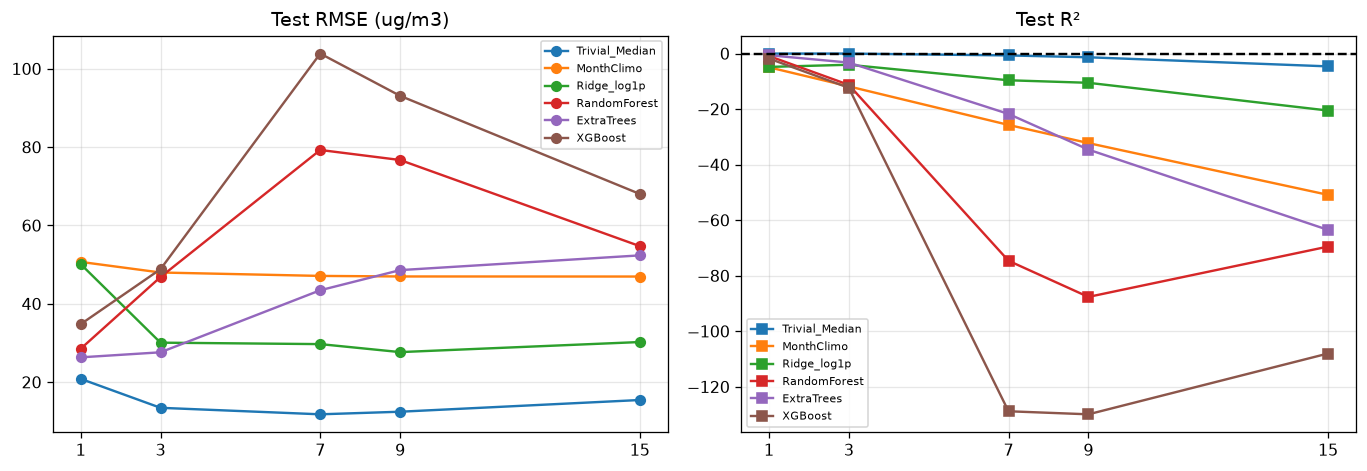

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for m in ['Trivial_Median','MonthClimo','Ridge_log1p','RandomForest','ExtraTrees','XGBoost']:
    s = reg_df[reg_df['Model']==m]
    axes[0].plot(s['Days'], s['RMSE'], marker='o', label=m); axes[1].plot(s['Days'], s['R2'], marker='s', label=m)
axes[1].axhline(0, color='black', ls='--'); axes[0].set_title('Test RMSE (ug/m3)'); axes[1].set_title('Test R²')
for ax in axes: ax.set_xticks([1,3,7,9,15]); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout()

## 15. Train+Val Refit Check (168h ExtraTrees)

In [15]:
et_tv = ExtraTreesClassifier(n_estimators=100, max_depth=8, min_samples_leaf=8, class_weight='balanced', random_state=42, n_jobs=-1).fit(np.vstack([X_tr,X_va]), np.concatenate([train_df['target_evt_any_168h'].values, val_df['target_evt_any_168h'].values]).astype(int))
print('Train-only ET 168h ROC:', cls_df[(cls_df['Horizon_H']==168)&(cls_df['Model']=='ExtraTrees_Cal')]['Test_ROC'].values[0], '| Train+Val ET:', round(roc_auc_score(y_te168, et_tv.predict_proba(X_te)[:,1]),4))

Train-only ET 168h ROC: 0.6884 | Train+Val ET: 0.6786


## 16. Top-10% Alert Lift Across 1–15 Days

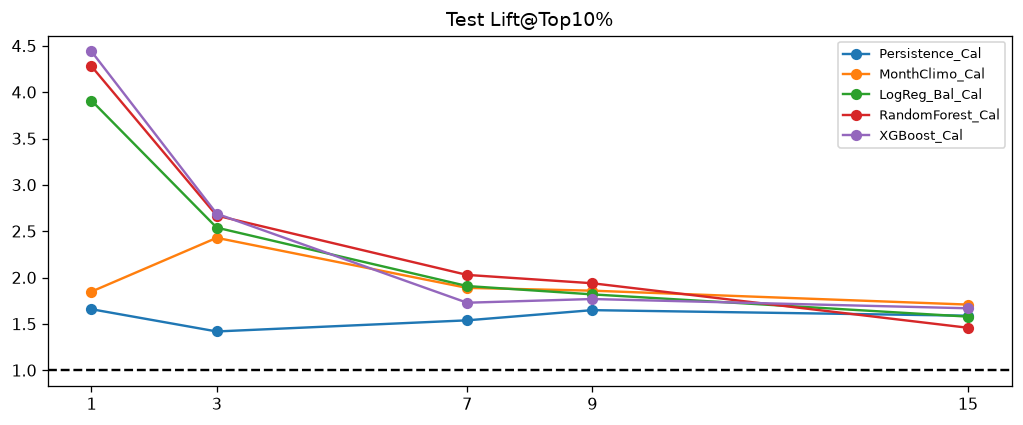

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for m in ['Persistence_Cal','MonthClimo_Cal','LogReg_Bal_Cal','RandomForest_Cal','XGBoost_Cal']:
    s = cls_df[cls_df['Model']==m]; ax.plot(s['Days'], s['Lift10'], marker='o', label=m)
ax.axhline(1.0, color='black', ls='--'); ax.set_xticks([1,3,7,9,15]); ax.set_title('Test Lift@Top10%'); ax.legend(fontsize=8); plt.tight_layout()

## 17. Residual Error Analysis (168h Clean PM10)

In [17]:
rf_r = RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=8, random_state=42, n_jobs=-1).fit(X_tr, np.log1p(train_df['target_avg_pm10_168h'].values))
p168 = np.expm1(rf_r.predict(X_te)); y168_te = test_df['target_avg_pm10_168h'].values; res = y168_te - p168
print(f'168h Residual Mean={res.mean():.2f}, Std={res.std():.2f}, P95_Abs={np.percentile(np.abs(res),95):.2f}')

168h Residual Mean=-55.22, Std=51.73, P95_Abs=166.86


## 18. Predicted vs Observed 168h Clean PM10 Time Series (Test)

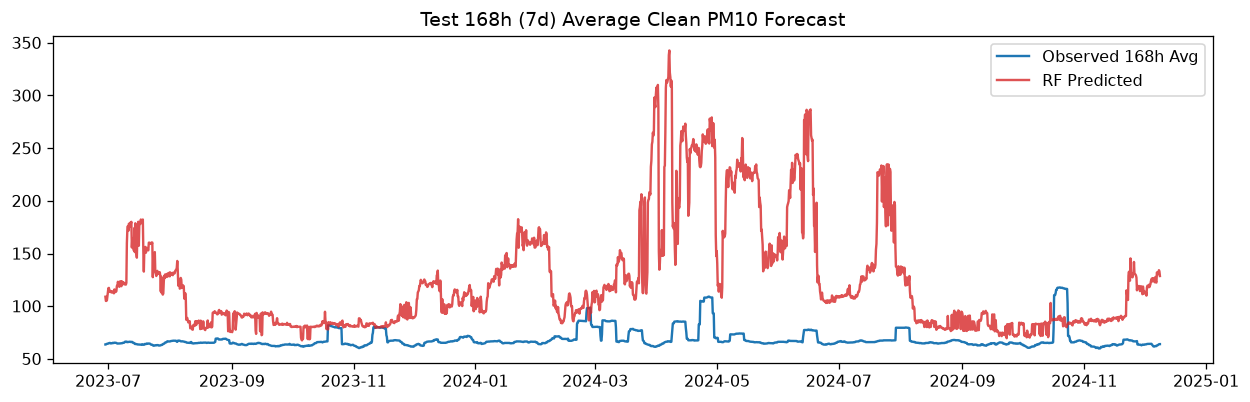

In [18]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(test_df['ts'], y168_te, label='Observed 168h Avg', color='#1f77b4')
ax.plot(test_df['ts'], p168, label='RF Predicted', color='#d62728', alpha=0.8)
ax.set_title('Test 168h (7d) Average Clean PM10 Forecast'); ax.legend(); plt.tight_layout()

## 19. Quantile Prediction Interval Coverage (10th–90th Percentile)

In [19]:
q10 = HistGradientBoostingRegressor(loss='quantile', quantile=0.10, max_iter=120, max_depth=5, random_state=42).fit(X_tr, train_df['target_avg_pm10_168h'].values).predict(X_te)
q90 = HistGradientBoostingRegressor(loss='quantile', quantile=0.90, max_iter=120, max_depth=5, random_state=42).fit(X_tr, train_df['target_avg_pm10_168h'].values).predict(X_te)
print(f'Nominal 80% Interval Test Coverage: {np.mean((y168_te>=q10)&(y168_te<=q90))*100:.1f}% | Mean Width: {np.mean(q90-q10):.1f}')

Nominal 80% Interval Test Coverage: 21.0% | Mean Width: 135.0


## 20. Paired 7-Day (28-Step) Block Bootstrap: RandomForest vs Persistence (168h)

In [20]:
rng = np.random.default_rng(42); blk = 28; nb = len(y_te168)//blk; diffs = []
pp = platt_cal(val_df['dust_rate_720h'].values, val_df['target_evt_any_168h'].values.astype(int), test_df['dust_rate_720h'].values)
pe = te_probs_168['RandomForest_Cal']
for _ in range(300):
    idx = np.concatenate([np.arange(s*blk,(s+1)*blk) for s in rng.integers(0, nb, size=nb)])
    if len(np.unique(y_te168[idx]))<2: continue
    diffs.append(roc_auc_score(y_te168[idx], pe[idx]) - roc_auc_score(y_te168[idx], pp[idx]))
print(f'168h Test ROC Diff (RF - Persistence): {np.mean(diffs):+.4f} 95% CI [{np.percentile(diffs,2.5):+.4f}, {np.percentile(diffs,97.5):+.4f}]')

168h Test ROC Diff (RF - Persistence): +0.1598 95% CI [+0.0683, +0.2440]


## 21. Seasonal Error Breakdown (Spring MAM vs Rest of Year)

In [21]:
spr = test_df['ts'].dt.month.isin([3,4,5]).values
print(f'Spring 168h RMSE: {root_mean_squared_error(y168_te[spr], p168[spr]):.2f} | Non-Spring: {root_mean_squared_error(y168_te[~spr], p168[~spr]):.2f}')

Spring 168h RMSE: 132.65 | Non-Spring: 56.78


## 22. Best Line A Classifier per Horizon

In [22]:
print(cls_df.sort_values(['Horizon_H','Test_ROC'], ascending=[True,False]).groupby('Horizon_H').first()[['Days','Model','Test_ROC','Test_PR','BSS','Lift10']].to_string())

           Days             Model  Test_ROC  Test_PR     BSS  Lift10
Horizon_H                                                           
24            1  RandomForest_Cal    0.8090   0.3143  0.3218    4.28
72            3  RandomForest_Cal    0.7167   0.3838  0.2724    2.67
168           7  RandomForest_Cal    0.7031   0.5657  0.1763    2.03
216           9       XGBoost_Cal    0.7156   0.6522  0.0301    1.77
360          15       XGBoost_Cal    0.7655   0.8311  0.1313    1.67


## 23. Best Line A Regressor per Horizon

In [23]:
print(reg_df.sort_values(['Horizon_H','RMSE']).groupby('Horizon_H').first()[['Days','Model','RMSE','R2','MAE']].to_string())

           Days           Model   RMSE      R2    MAE
Horizon_H                                            
24            1  Trivial_Median  20.86 -0.0056   5.69
72            3  Trivial_Median  13.46 -0.0079   5.38
168           7  Trivial_Median  11.80 -0.6741  10.64
216           9  Trivial_Median  12.46 -1.3389  11.58
360          15  Trivial_Median  15.45 -4.6141  14.70


## 24. Export Verification

In [24]:
for fn in ['nb02_line_a_5fold_cv_hourly.csv','nb02_line_a_classification_hourly.csv','nb02_line_a_regression_hourly.csv']:
    assert (RESULTS_DIR / fn).exists()
print('Line A clean hourly CSVs verified.')

Line A clean hourly CSVs verified.


## 25. Notebook 02 Summary

In [25]:
print('NB02 Complete on Clean Hourly Data.')

NB02 Complete on Clean Hourly Data.
